# Простейший персептрон. Правило Хебба

## Imports

In [15]:
import numpy as np
import helpers as h
from datetime import datetime

import matplotlib.pyplot as plt
import seaborn as sns

import importlib
importlib.reload(h)
curr_time = datetime.now()
print(f"Модули обновлены.\nВремя: {curr_time.strftime('%Y-%m-%d %H:%M:%S')}")

Модули обновлены.
Время: 2026-10-02 14:27:07


In [12]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [10, 8]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

## Задание

In [65]:
data = np.array([
    [143, 85, 0],
    [113, 140, 0],
    [68, 209, 0],
    [125, 200, 0],
    [124, 230, 0],
    [185, 158, 1],
    [215, 157, 1],
    [202, 220, 1],
    [233, 89, 1],
    [279, 138, 1]
], dtype="float")

neg_coords = np.where(data[:, -1] == 0)[0]
pos_coords = np.where(data[:, -1] == 1)[0]

simulation_coords = data[:, :2]
y_true = data[:, -1].astype("int")

init_coord = np.array([145, 170], dtype="float")

coords = h.to_new_coordinate_sytem(simulation_coords, init_coord)
scale = 215 - 145
coords = coords / scale

In [70]:
solution = h.find_solution(y_true, coords, random_state=100)

h.print_results(*solution)

Класс  |   x0   |   x1   |   x2   |     w0     |     w1     |     w2     |     z      | Предсказание  | Верно? 
---------------------------------------------------------------------------------------------------------------
     0 |      1 |     -0 |      1 |     0.0868 |    -0.4433 |    -0.1510 |    -0.0838 |             0 | True
     0 |      1 |     -0 |      0 |     0.0868 |    -0.4433 |    -0.1510 |     0.2247 |             1 | False
     0 |      1 |     -1 |     -1 |    -0.9132 |     0.0139 |    -0.5795 |    -0.6056 |             0 | True
     0 |      1 |     -0 |     -0 |    -0.9132 |     0.0139 |    -0.5795 |    -0.6688 |             0 | True
     0 |      1 |     -0 |     -1 |    -0.9132 |     0.0139 |    -0.5795 |    -0.4206 |             0 | True
     1 |      1 |      1 |      0 |    -0.9132 |     0.0139 |    -0.5795 |    -1.0046 |             0 | False
     1 |      1 |      1 |      0 |     0.0868 |     0.5853 |    -0.4081 |     0.5963 |             1 | True
     1 |   

In [71]:
y_true, X, all_weights, zs, y_preds, conclusions = solution
weights = all_weights[-1]
weights

array([-0.91319012,  2.34245306,  0.00617804])

In [72]:
def plot_line(xs, weights):
    w0, w1, w2 = weights
    new_ys = (-w0 -w1 * xs) / w2
    plt.plot(xs, new_ys)

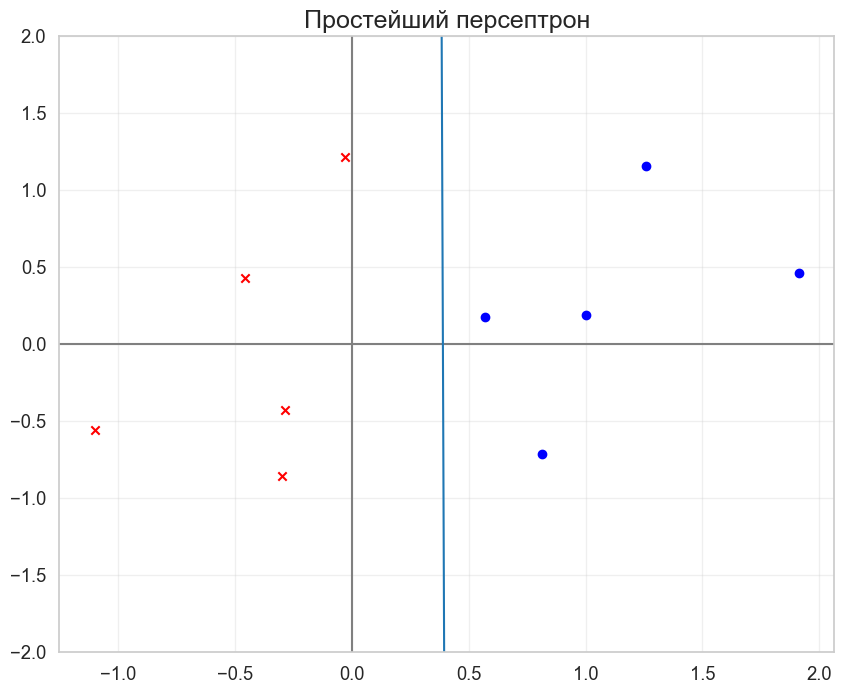

In [74]:
xs = X[:, 1]
ys = X[:, 2]
pos_xs, pos_ys = xs[pos_coords], ys[pos_coords]
neg_xs, neg_ys = xs[neg_coords], ys[neg_coords]
plt.scatter(neg_xs, neg_ys, color="red", marker="x")
plt.scatter(pos_xs, pos_ys, color="blue")
plt.axhline(0, color="gray")
plt.axvline(0, color="gray")
plot_line(xs, weights)
plt.title("Простейший персептрон", size=18)
plt.ylim(-2, 2)
plt.grid(alpha=0.3)